# ML-05b (Python) : Séries temporelles classiques — stationnarité, ACF/PACF, ARIMA/SARIMA, lissage exponentiel

> **Socle statistique.** Ce notebook pose les fondations que [ML-05-TimeSeries-CSharp](ML-05-TimeSeries-CSharp.ipynb) (SSA, ML.NET) applique en boîte noire et que [ML-05-TimeSeries-Python](ML-05-TimeSeries-Python.ipynb) (STL + SARIMA) applique mécaniquement : **tester la stationnarité**, **lire une ACF/PACF**, **ajuster un ARIMA**, **comprendre pourquoi différencier**, et **comparer honnêtement** ARIMA, lissage exponentiel et baseline naïve.



## Objectifs d'apprentissage

À l'issue de ce notebook, vous saurez :

1. **Décomposer** une série en tendance + saisonnalité + résidu (`seasonal_decompose`), et lire chaque composante.
2. **Tester la stationnarité** avec ADF (H0, p-value, conclusion écrite) et **différencier** pour la rétablir.
3. **Lire une ACF/PACF** pour identifier les ordres `p` et `q` (les barres hors bande de confiance), y compris sur un AR(2) synthétique.
4. **Ajuster un SARIMA** depuis la lecture ACF/PACF, **diagnostiquer** les résidus (ACF plate + Ljung-Box) et **prévoir** avec intervalle de confiance.
5. **Lisser** par simple / Holt / Holt-Winters, et savoir quand le lissage égale ARIMA à moindre coût intellectuel.
6. **Comparer honnêtement** (ARIMA vs Holt-Winters vs naïf) sur un backtest glissant — la baseline naïve qui gagne parfois **est** la leçon.

**Relation aux autres notebooks** : ML-05 (SSA) = le même problème en ML.NET ; ML-05-TimeSeries-Python = l'application STL+SARIMA ; ce notebook = le **pourquoi** statistique que les deux supposent. Du côté quant, les notebooks HAR de QuantConnect poussent la même famille vers les features modernes (voir la conclusion).

**Navigation** : [Version C#](ML-05b-Series-Temporelles-Classiques-CSharp.ipynb) · [Index](README.md).

**Prérequis** : statistiques élémentaires, tableaux, régression ; **durée indicative** : 90 minutes.


In [1]:
# Imports : pandas (données), statsmodels (décomposition, ADF, ACF/PACF, ARIMA/SARIMA,
# lissage exponentiel, Ljung-Box), matplotlib (visualisation).
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")
warnings.filterwarnings("ignore", message="No frequency", category=UserWarning, module="statsmodels")
plt.rcParams["figure.dpi"] = 110

print("pandas, numpy, statsmodels (décomposition, ADF, ACF/PACF, ARIMA/SARIMA, lissage), matplotlib chargés")
import sys, statsmodels, scipy, hashlib
print(f"CPython {sys.version.split()[0]} | NumPy {np.__version__} | statsmodels {statsmodels.__version__} | SciPy {scipy.__version__}")


pandas, numpy, statsmodels (décomposition, ADF, ACF/PACF, ARIMA/SARIMA, lissage), matplotlib chargés
CPython 3.13.16 | NumPy 2.4.4 | statsmodels 0.14.6 | SciPy 1.17.0


## Partie 1 : Décomposition — tendance + saisonnalité + résidu

On commence par **voir** ce qui compose une série temporelle. Le modèle additif classique est :

```
série(t) = tendance(t) + saisonnalité(t) + résidu(t)
```

`statsmodels.seasonal_decompose` sépare ces trois composantes. On le démontre d'abord sur une série **synthétique franche** (tendance + saisonnalité 12 + bruit), pour que les trois composantes soient lisibles, puis sur la **vraie série du dépôt** (`daily-sales.csv`, celle que ML-05 utilise).

### Exemple guidé — série synthétique franche

La cellule ci-dessous fabrique la série : une tendance linéaire de pente 0,4, une saisonnalité sinusoïdale de période 12, et un bruit gaussien.

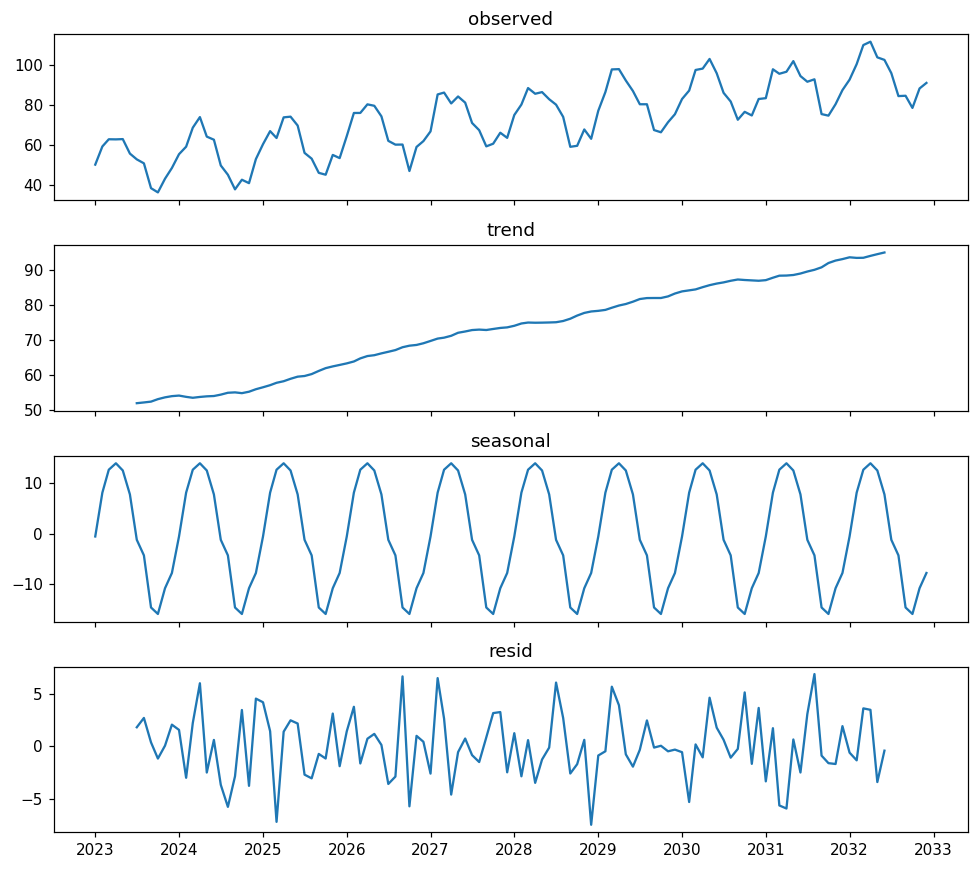

Composante tendance : moyenne = 73.2
Amplitude saisonnière : 29.9 (max - min de la composante seasonale)
Résidu : moyenne = 0.053 (attendu ~0), écart-type = 3.07


In [2]:
# Série synthétique franche : tendance linéaire + saisonnalité de période 12 + bruit gaussien.
rng = np.random.default_rng(7)
n = 120
t = np.arange(n)
trend = 50 + 0.4 * t
seasonal = 15 * np.sin(2 * np.pi * t / 12)
noise = rng.normal(0, 4, n)
y_synth = trend + seasonal + noise

s_synth = pd.Series(y_synth, index=pd.date_range("2023-01-01", periods=n, freq="MS"))
res_synth = seasonal_decompose(s_synth, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, name in zip(axes, ["observed", "trend", "seasonal", "resid"]):
    ax.plot(getattr(res_synth, name))
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("Composante tendance : moyenne = {:.1f}".format(res_synth.trend.mean()))
print("Amplitude saisonnière : {:.1f} (max - min de la composante seasonale)".format(
    res_synth.seasonal.max() - res_synth.seasonal.min()))
print("Résidu : moyenne = {:.3f} (attendu ~0), écart-type = {:.2f}".format(
    res_synth.resid.mean(), res_synth.resid.std()))

### Interprétation de la décomposition synthétique

La tendance croît de **0,4 par mois** dans le générateur. La décomposition donne une tendance moyenne voisine de 73 et une amplitude saisonnière proche de 30 ; les valeurs exactes sont imprimées. La composante saisonnière est périodique par construction de l'algorithme : cela ne prouve pas une périodicité parfaite d'une série observée. Le résidu, de moyenne proche de zéro et d'écart-type proche de 3, reste de l'ordre du bruit injecté (écart-type 4), dont la décomposition absorbe une partie. Une moyenne et une variance empiriques ne suffisent pas à établir la stationnarité ; celle du bruit est ici une hypothèse du générateur.

La prévision cherche à exploiter tendance et saisonnalité sans confondre le bruit du tirage avec un signal prévisible.


### Application à la série fournie dans le dépôt — daily-sales.csv

On utilise exactement le fichier de ventes quotidiennes partagé avec ML-05 : période 2023–2024, cycle hebdomadaire (période 7). Le fichier est une donnée pédagogique du dépôt ; son utilisation ne constitue pas une affirmation sur une provenance commerciale indépendante. La décomposition est calculée sur l'entraînement 2023 seulement.


=== Statistiques du dataset ===
Période totale : 2023-01-01 -> 2024-12-31 (731 jours)
Entraînement (2023) : 365 jours | ventes moyennes = 124.5
Test (2024)         : 366 jours | ventes moyennes = 174.3
Croissance 2023 -> 2024 : +40.0%


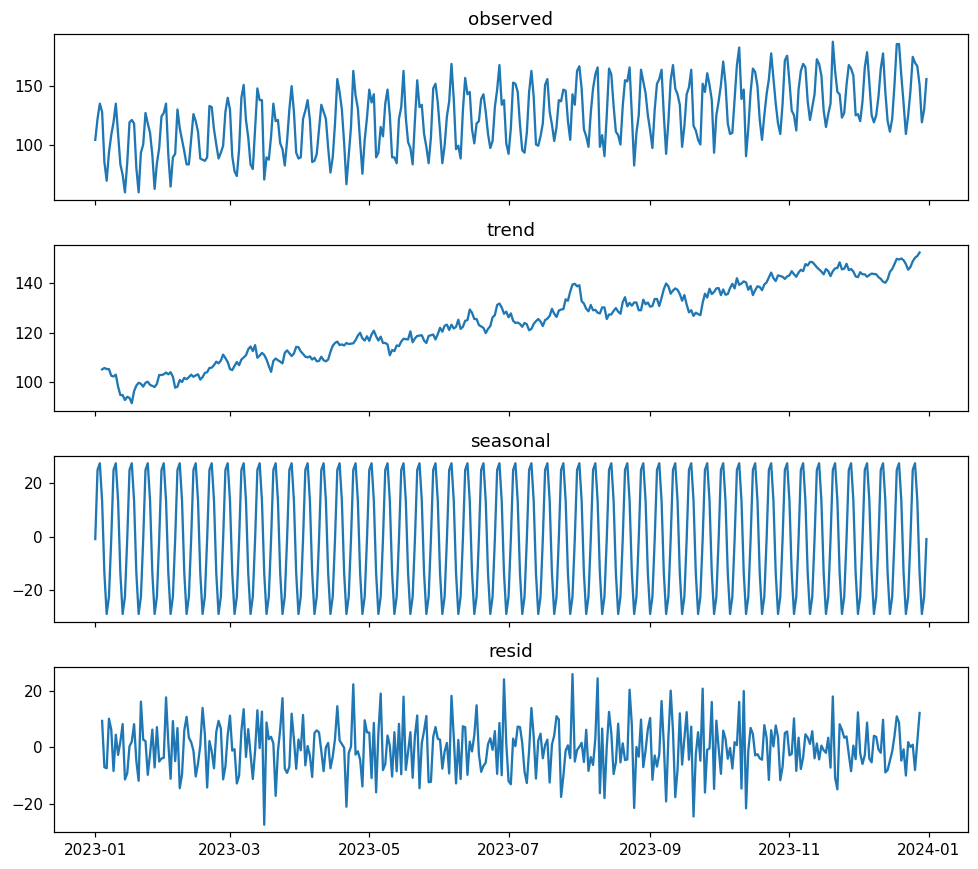

Tendance (moyenne horaire 2023) : 105.1 -> 152.6


In [3]:
# Charger la vraie série du dépôt (celle de ML-05), l'indexer par date, fréquence quotidienne.
df = pd.read_csv("daily-sales.csv", parse_dates=["Date"], index_col="Date").sort_index().asfreq("D")
sales = df["Sales"].astype(float)

# Split explicite : entraînement 2023, test 2024 (comme le jumeau ML.NET).
train = sales[sales.index.year == 2023]
test = sales[sales.index.year == 2024]

print("=== Statistiques du dataset ===")
print("Période totale : {} -> {} ({} jours)".format(
    sales.index.min().date(), sales.index.max().date(), len(sales)))
print("Entraînement (2023) : {} jours | ventes moyennes = {:.1f}".format(len(train), train.mean()))
print("Test (2024)         : {} jours | ventes moyennes = {:.1f}".format(len(test), test.mean()))
print("Croissance 2023 -> 2024 : {:+.1f}%".format((test.mean() - train.mean()) / train.mean() * 100))

# Décomposition sur l'entraînement (période 7 = saisonnalité hebdomadaire).
res_train = seasonal_decompose(train, model="additive", period=7)
fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, name in zip(axes, ["observed", "trend", "seasonal", "resid"]):
    ax.plot(getattr(res_train, name))
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("Tendance (moyenne horaire 2023) : {:.1f} -> {:.1f}".format(
    res_train.trend.dropna().iloc[0], res_train.trend.dropna().iloc[-1]))

### Interprétation sur la série du dépôt

La tendance 2023 augmente d'environ 105 à 153 sur les valeurs disponibles après lissage ; les moyennes annuelles imprimées passent d'environ 124,5 à 174,3, soit 40 % de croissance. Les panneaux montrent le cycle hebdomadaire et les résidus, sans mesurer ici une part de variance expliquée. Ce changement de niveau motive le diagnostic de racine unité et la comparaison de transformations ; il ne faut pas déduire un ordre de différenciation de la seule présence d'une saisonnalité.


## Partie 2 : Stationnarité — le test ADF et la différenciation

La partie ARMA d'un ARIMA décrit une série après différenciation et suppose une dynamique stationnaire. Au sens faible, la moyenne et la variance sont constantes et la covariance dépend du retard, pas de la date. Une saisonnalité déterministe et une racine unité saisonnière sont des objets distincts.

### Le test ADF

- H0 : présence d'une racine unité dans la spécification testée.
- H1 : absence de cette racine unité autour des termes déterministes inclus.
- p < 0,05 : rejet de H0 dans ce test ; p ≥ 0,05 : non-rejet, sans preuve que H0 est vraie.

Les appels gardent les défauts statsmodels : constante et retard choisi automatiquement. Une tendance déterministe omise, la puissance du test et les changements de régime limitent la conclusion. On examine niveau et différence première ; ce diagnostic oriente une modélisation, sans décider mécaniquement d ou D.


**Portée descriptive** : ces diagnostics utilisent ici les **731 jours**, dont 2024. Ils ne constituent pas une sélection prospective sans fuite des transformations.


In [4]:
def adf_report(series, name):
    """Rend le test ADF et une conclusion écrite (rejet / non-rejet de H0)."""
    stat = adfuller(series.dropna())
    adf_stat, p_value, used_lag, nobs = stat[0], stat[1], stat[2], stat[3]
    conclusion = "racine unité rejetée dans cette spécification" if p_value < 0.05 else "racine unité non rejetée ; H0 n’est pas démontrée"
    print("{} : ADF stat = {:.2f} | p-value = {:.4f} | lags = {} | n = {}".format(
        name, adf_stat, p_value, used_lag, nobs))
    print("   -> {}".format(conclusion))
    return p_value

print("=== Test ADF ===")
p_level = adf_report(sales, "sales (niveau)")
p_diff = adf_report(sales.diff(), "sales (différenciée, d=1)")

print("ADF : constante et sélection automatique du retard ; d et D restent des choix de modélisation à évaluer.")


=== Test ADF ===
sales (niveau) : ADF stat = -0.78 | p-value = 0.8246 | lags = 20 | n = 710
   -> racine unité non rejetée ; H0 n’est pas démontrée
sales (différenciée, d=1) : ADF stat = -10.94 | p-value = 0.0000 | lags = 20 | n = 709
   -> racine unité rejetée dans cette spécification
ADF : constante et sélection automatique du retard ; d et D restent des choix de modélisation à évaluer.


### Interprétation — pourquoi examiner une différence

Dans le run, le niveau donne p ≈ 0,825 et la différence première une p-value très inférieure au seuil : la racine unité n'est pas rejetée en niveau et est rejetée après différence, dans cette spécification. Cela rend d=1 plausible pour l'expérience suivante, sans prouver une stationnarité universelle ni imposer la différenciation saisonnière D=1. Cette dernière est un choix de la petite grille, pas une conséquence automatique du cycle hebdomadaire.

### Exercice 1 — différence saisonnière et ADF effectif

Pour un tableau reçu et un retard donné, calculez la différence, appliquez le vrai ADF et renvoyez valeurs, p-value et décision (`rejet` / `non-rejet`). Les mêmes étapes doivent fonctionner au retard 7 sur les ventes, au retard 3 sur une autre série et au retard 1 sur une tendance quadratique.

Étape 1 : aligner chaque différence sur les deux observations espacées du retard demandé. Étape 2 : ajuster le vrai test ADF sur le tableau fini. Étape 3 : distinguer décision de test et preuve de stationnarité. Le garde contrôle trois fixtures, les formes, les valeurs et la décision ; une p-value constante ne suffit pas.


In [5]:
# Exercice 1 : différence saisonnière et vrai ADF
# TODO étudiant : Étape 1, aligner les différences ; Étape 2, calculer ADF ; Étape 3, décider rejet/non-rejet.
def difference_saisonniere(values, lag):
    return None  # TODO étudiant : dict avec exactement values, pvalue, decision

def verifier_difference(response):
    try:
        if not callable(response):
            return False
        fixtures = [(sales.to_numpy(), 7), (30 + .2*np.arange(120) + 3*np.sin(np.arange(120)*.71) + np.cos(np.arange(120)*1.9), 3), (np.arange(120)**2/120 + .03*np.sin(np.arange(120)*.71), 1)]
        for values, lag in fixtures:
            actual = response(values.copy(), lag)
            expected = values[lag:] - values[:-lag]
            p = float(adfuller(expected)[1])
            if not isinstance(actual, dict) or set(actual) != {"values", "pvalue", "decision"}:
                return False
            arr = np.asarray(actual["values"])
            if arr.shape != expected.shape or not np.isfinite(arr).all() or not np.allclose(arr, expected, rtol=0, atol=1e-10):
                return False
            if not np.isscalar(actual["pvalue"]) or not np.isfinite(actual["pvalue"]) or not np.isclose(actual["pvalue"], p, rtol=0, atol=1e-9) or actual["decision"] != ("rejet" if p < .05 else "non-rejet"):
                return False
        return True

    except (TypeError, ValueError, OverflowError, AttributeError, IndexError, KeyError):
        return False

print("Exercice 1 à compléter" if difference_saisonniere(sales.to_numpy(), 7) is None else f"Exercice 1 valide : {verifier_difference(difference_saisonniere)}")


Exercice 1 à compléter


## Partie 3 : ACF / PACF — lire les ordres p et q

L'ACF mesure la corrélation à chaque retard ; la PACF isole une relation au retard k conditionnellement aux retards intermédiaires. Pour des familles idéales et stationnaires, la PACF d'un AR(p) et l'ACF d'un MA(q) présentent une coupure théorique. Les estimations finies n'ont pas cette netteté garantie : un franchissement isolé, parmi de nombreux retards inspectés, ne choisit pas un ordre certain.

Les graphiques montrent les intervalles ponctuels statsmodels à 95 % (ACF : approximation de Bartlett ; PACF : méthode ywm). Le repère 2/√n utilisé pour compter les retards est une approximation séparée, pas la définition de tous les intervalles du graphique. Le retard zéro vaut 1 et n'est pas une preuve de dépendance temporelle.

### Exemple guidé — AR(2) synthétique

On conserve 400 observations et la récurrence 0,6 y[t−1] − 0,3 y[t−2] + bruit. Les retards 1 et 2 doivent être lus dans leur contexte ; un résultat fini reste une estimation.


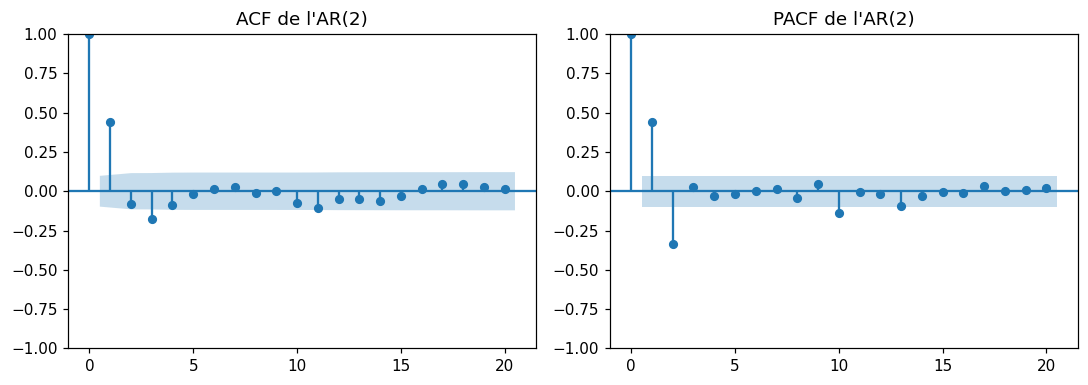

Valeur de la PACF : lags 1-5 = [np.float64(0.438), np.float64(-0.336), np.float64(0.024), np.float64(-0.032), np.float64(-0.017)]
Band de confiance : +-0.100
Retards significatifs (|PACF| > bande) : [1, 2, 10]
-> les retards 1 et 2 ressortent ; les franchissements isolés ne sélectionnent pas un ordre avec certitude.


In [6]:
# AR(2) synthétique : y_t = 0.6 y_{t-1} - 0.3 y_{t-2} + eps
rng_ar = np.random.default_rng(11)
N = 400
y_ar2 = np.zeros(N)
for i in range(2, N):
    y_ar2[i] = 0.6 * y_ar2[i - 1] - 0.3 * y_ar2[i - 2] + rng_ar.normal(0, 1)
y_ar2 = pd.Series(y_ar2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
plot_acf(y_ar2, ax=axes[0], lags=20, alpha=0.05)
plot_pacf(y_ar2, ax=axes[1], method="ywm", lags=20, alpha=0.05)
axes[0].set_title("ACF de l'AR(2)")
axes[1].set_title("PACF de l'AR(2)")
plt.tight_layout()
plt.show()

# Retards dont la PACF sort de la bande (~ +-2/sqrt(N)).
n_len = len(y_ar2)
band = 2.0 / np.sqrt(n_len)
pacf_vals = pacf(y_ar2, method="ywm", nlags=20)
sig_lags = [k for k, v in enumerate(pacf_vals) if k > 0 and abs(v) > band]
print("Valeur de la PACF : lags 1-5 = {}".format([round(pacf_vals[k], 3) for k in range(1, 6)]))
print("Band de confiance : +-{:.3f}".format(band))
print("Retards significatifs (|PACF| > bande) : {}".format(sig_lags))
print("-> les retards 1 et 2 ressortent ; les franchissements isolés ne sélectionnent pas un ordre avec certitude.")

### Interprétation de la PACF de l'AR(2)

Les estimations aux retards 1 et 2 sont voisines de **0,438** et **−0,336**, bien au-delà du repère ±0,100. Un autre franchissement apparaît au retard 10 : il ne suffit pas à transformer le générateur AR(2) connu en AR(10). C'est une illustration de l'incertitude et de la multiplicité des retards inspectés, pas une sélection automatique de modèle.

### Exercice 2 — calcul et lecture reproductibles des corrélogrammes

Complétez une fonction générique renvoyant ACF, PACF ywm et liste ordonnée des retards **strictement positifs** dont |PACF| dépasse 2/√n. Contrôlez les ventes différenciées jusqu'au retard 40 et une autre série jusqu'au retard 10. Les tableaux sont contrôlés contre statsmodels ; les dimensions, valeurs finies et exclusion du retard zéro comptent. La liste est un diagnostic descriptif, pas un ordre p démontré.


In [7]:
# Exercice 2 : corrélogrammes et lecture (retards positifs seulement)
# Le calcul guidé du source est conservé ; une fonction générique reste à compléter.
diff_series = sales.diff().dropna()
n2 = len(diff_series)
band2 = 2.0 / np.sqrt(n2)
pacf_diff = pacf(diff_series, method="ywm", nlags=40)
sig_diff = [k for k, v in enumerate(pacf_diff) if k > 0 and abs(v) > band2]
print(f"Retards positifs PACF hors repère : {sig_diff}")

def lire_correlogramme(values, lags):
    # TODO étudiant : Étape 1 ACF/PACF ; Étape 2 retards hors repère ; Étape 3 interpréter sans ordre imposé.
    return None  # TODO étudiant : dict acf, pacf, significant_lags

def verifier_correlations(response):
    try:
        if not callable(response):
            return False
        for values, lags in [(diff_series.to_numpy(), 40), (y_ar2.to_numpy(), 10)]:
            a = response(values.copy(), lags)
            if not isinstance(a, dict) or set(a) != {"acf", "pacf", "significant_lags"}:
                return False
            refs = [acf(values, nlags=lags), pacf(values, method="ywm", nlags=lags)]
            for key, ref in zip(["acf", "pacf"], refs):
                arr = np.asarray(a[key])
                if arr.shape != ref.shape or not np.isfinite(arr).all() or not np.allclose(arr, ref, rtol=0, atol=1e-9):
                    return False
            expected = [k for k in range(1, lags+1) if abs(refs[1][k]) > 2/np.sqrt(len(values))]
            if list(a["significant_lags"]) != expected:
                return False
        return True

    except (TypeError, ValueError, OverflowError, AttributeError, IndexError, KeyError):
        return False

print("Exercice 2 à compléter" if lire_correlogramme(diff_series.to_numpy(), 40) is None else f"Exercice 2 valide : {verifier_correlations(lire_correlogramme)}")

if lire_correlogramme(diff_series.to_numpy(), 40) is not None and verifier_correlations(lire_correlogramme):
    reponse = lire_correlogramme(diff_series.to_numpy(), 40)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, key in zip(axes, ["acf", "pacf"]):
        vals = np.asarray(reponse[key])
        raw = acf(diff_series.to_numpy(), nlags=40, alpha=.05) if key == "acf" else pacf(diff_series.to_numpy(), method="ywm", nlags=40, alpha=.05)
        ci = raw[1] - vals[:, None]
        ax.stem(np.arange(len(vals)), vals)
        ax.fill_between(np.arange(len(vals)), ci[:, 0], ci[:, 1], alpha=.2)
        ax.set_title(f"{key.upper()} des ventes différenciées")
        ax.set_xlabel("retard"); ax.set_ylabel("corrélation")
    plt.tight_layout(); plt.show()
    print("Lecture : retards positifs hors repère", reponse["significant_lags"], "; une barre n'impose pas seule un ordre.")


Retards positifs PACF hors repère : [1, 2, 3, 4, 5, 6, 7, 9, 11, 12, 13, 16, 20, 21, 25, 26]
Exercice 2 à compléter


## Partie 4 : ARIMA / SARIMA — ajuster, diagnostiquer, prévoir

Le diagnostic précédent motive l'étude de d=1. On fixe aussi D=1 et s=7 comme choix expérimental de cette grille : l'ADF non saisonnier ne démontre pas la présence d'une racine unité saisonnière. Les quatre ordres courts (p,q) et quatre couples saisonniers (P,Q), chacun dans {0,1}, donnent **16 ajustements** sur les 365 jours de 2023.

L'AIC classe ces configurations à données et différenciations communes ; la convergence numérique doit être examinée séparément. Les diagnostics résiduels et le test hors échantillon complètent ce critère. Aucun modèle qui échoue n'est remplacé silencieusement par la baseline.


Le backtest ci-dessous est conditionné aux choix **d=D=1 et s=7 fixés** ; il évalue les ajustements ainsi spécifiés, pas un processus complet de choix des transformations ignorant le futur.


In [8]:
# Grille SARIMA : d=1, D=1, s=7 sont des choix expérimentaux distincts du verdict ADF.
# et on compare (p,q) x (P,Q) par AIC. Grid volontairement petite (<= 5 min CPU).
from itertools import product

train_w = train  # 2023 (365 points)

def fit_sarima(order, sorder, data):
    return SARIMAX(data, order=order, seasonal_order=sorder).fit(disp=False)

best_aic, best_cfg = None, None
rows = []
for (p, q), (P, Q) in product(product([0, 1], [0, 1]), product([0, 1], [0, 1])):
    order, sorder = (p, 1, q), (P, 1, Q, 7)
    m = fit_sarima(order, sorder, train_w)
    if m is not None and np.isfinite(m.aic):
        rows.append((order, sorder, round(m.aic, 1)))
        if best_aic is None or m.aic < best_aic:
            best_aic, best_cfg = m.aic, (order, sorder)

print("=== Grille SARIMA (AIC) ===")
for order, sorder, aic in sorted(rows, key=lambda r: r[2])[:8]:
    print("  SARIMA{} x {} : AIC = {}".format(order, sorder, aic))
print()
print("Meilleure configuration : SARIMA{} x {} (AIC = {:.1f})".format(
    best_cfg[0], best_cfg[1], best_aic))
print(f"Grille complète : {len(rows)}/16 ajustements ; aucune exception transformée en modèle de repli.")


=== Grille SARIMA (AIC) ===
  SARIMA(0, 1, 1) x (0, 1, 1, 7) : AIC = 2666.7
  SARIMA(1, 1, 1) x (0, 1, 1, 7) : AIC = 2667.5
  SARIMA(0, 1, 1) x (1, 1, 1, 7) : AIC = 2668.5
  SARIMA(1, 1, 1) x (1, 1, 1, 7) : AIC = 2669.4
  SARIMA(0, 1, 1) x (1, 1, 0, 7) : AIC = 2781.8
  SARIMA(1, 1, 1) x (1, 1, 0, 7) : AIC = 2783.4
  SARIMA(1, 1, 0) x (0, 1, 1, 7) : AIC = 2813.6
  SARIMA(1, 1, 0) x (1, 1, 1, 7) : AIC = 2815.6

Meilleure configuration : SARIMA(0, 1, 1) x (0, 1, 1, 7) (AIC = 2666.7)
Grille complète : 16/16 ajustements ; aucune exception transformée en modèle de repli.


### Prévision hors échantillon

La grille est classée sur le seul entraînement. La cellule suivante réajuste sa meilleure configuration et prévoit les **366 jours** de 2024, avec intervalle conditionnel à 95 % et MAPE sur les trente premiers jours.


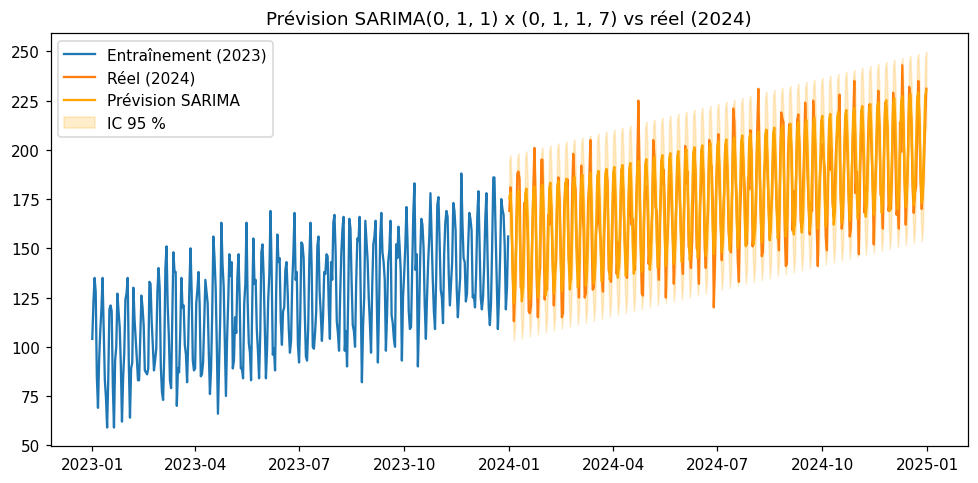

AIC du modèle final : 2666.7
MAPE (30 premiers jours de 2024) : 5.61 %


In [9]:
# Ajuster le meilleur SARIMA sur l'entraînement 2023 et prévoir 2024 avec IC 95 %.
best_order, best_sorder = best_cfg
model_final = SARIMAX(train_w, order=best_order, seasonal_order=best_sorder).fit(disp=False)

n_test = len(test)
forecast_res = model_final.get_forecast(n_test)
forecast_mean = forecast_res.predicted_mean
forecast_ci = forecast_res.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(train.index, train, label="Entraînement (2023)")
ax.plot(test.index, test, label="Réel (2024)")
ax.plot(forecast_mean.index, forecast_mean, label="Prévision SARIMA", color="orange")
ax.fill_between(forecast_mean.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1],
                color="orange", alpha=0.2, label="IC 95 %")
ax.legend()
ax.set_title("Prévision SARIMA{} x {} vs réel (2024)".format(best_order, best_sorder))
plt.tight_layout()
plt.show()

# Métrique simple : MAPE sur les 30 premiers jours de test.
first30 = test[:30]
mape = np.mean(np.abs((first30 - forecast_mean[:30]) / first30)) * 100
print("AIC du modèle final : {:.1f}".format(model_final.aic))
print("MAPE (30 premiers jours de 2024) : {:.2f} %".format(mape))

### Diagnostics des résidus : une question à tester

On examine l'ACF des résidus et le test Ljung–Box aux retards 5 et 10. L'hypothèse nulle de ce test porte sur l'absence d'autocorrélation jusqu'au retard considéré ; son non-rejet ne démontre ni indépendance, ni normalité, ni bruit blanc. Comme le source, l'expérience conserve tous les résidus et model_df=0 : les degrés de liberté liés à l'ajustement et le démarrage du filtre sont des limites de cette lecture.


=== ACF des résidus (premiers retards) ===
  lags 1-10 : [np.float64(0.0), np.float64(-0.02), np.float64(0.05), np.float64(-0.14), np.float64(0.01), np.float64(0.13), np.float64(-0.08), np.float64(-0.05), np.float64(0.05), np.float64(-0.05)]

=== Test Ljung-Box (H0 : pas d'autocorrélation des résidus) ===
  lag 5 : p = 0.109 -> absence d’autocorrélation non rejetée
  lag 10 : p = 0.031 -> rejet d’absence d’autocorrélation


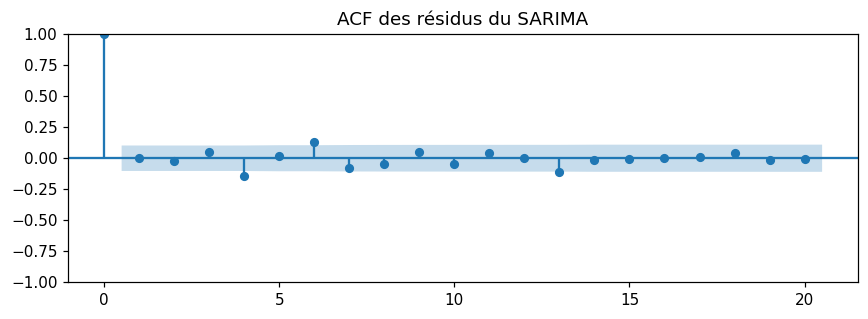

Diagnostic non ajusté model_df=0, résidus complets ; non-rejet ne prouve pas un bruit blanc.


In [10]:
# Diagnostics des résidus : ACF plate + Ljung-Box.
resid = model_final.resid.dropna()

print("=== ACF des résidus (premiers retards) ===")
acf_resid = acf(resid, nlags=15)
print("  lags 1-10 : {}".format([round(acf_resid[k], 2) for k in range(1, 11)]))

print()
print("=== Test Ljung-Box (H0 : pas d'autocorrélation des résidus) ===")
lb = acorr_ljungbox(resid, lags=[5, 10], return_df=True)
for lag in [5, 10]:
    p = lb.loc[lag, "lb_pvalue"]
    verdict = "absence d’autocorrélation non rejetée" if p >= 0.05 else "rejet d’absence d’autocorrélation"
    print("  lag {} : p = {:.3f} -> {}".format(lag, p, verdict))

fig, ax = plt.subplots(figsize=(8, 3))
plot_acf(resid, ax=ax, lags=20)
ax.set_title("ACF des résidus du SARIMA")
plt.tight_layout()
plt.show()
print("Diagnostic non ajusté model_df=0, résidus complets ; non-rejet ne prouve pas un bruit blanc.")


### Interprétation des diagnostics

L'ACF présente notamment des valeurs proches de **−0,14 au retard 4** et **0,13 au retard 6**. Le Ljung–Box donne, dans le run, p ≈ **0,109** au retard 5 et **0,031** au retard 10 : absence d'autocorrélation non rejetée au premier, rejetée au second. Une petite p-value ne mesure pas la taille d'un effet ; ces résultats n'autorisent pas à certifier un bruit blanc ou une adéquation globale. L'intervalle de prévision est conditionnel au modèle ajusté, sans couvrir toute l'incertitude de sélection.

### Exercice 3 — vrai ARIMA sans saisonnalité

Complétez la prévision par ARIMA(1,1,1), sans terme saisonnier, pour les données et l'horizon reçus. Le garde compare les prévisions de deux séries et horizons différents au vrai moteur ; MAPE est recalculée depuis les prévisions, pas acceptée comme un chiffre déclaré. Comparez ensuite les 30 premiers jours au SARIMA sans imposer de gagnant général.


In [11]:
# Exercice 3 : vrai ARIMA(1,1,1), sans terme saisonnier
# TODO étudiant : Étape 1 ajuster le moteur ; Étape 2 prévoir l’horizon ; Étape 3 comparer les MAPE calculées.
def prevoir_arima(values, steps):
    return None  # TODO étudiant : tableau des prévisions

def verifier_arima(response):
    try:
        if not callable(response):
            return False
        for values, steps in [(train.to_numpy(), 30), (100 + 2*y_ar2.to_numpy()[:100], 7)]:
            a = np.asarray(response(values.copy(), steps))
            expected = np.asarray(ARIMA(values, order=(1,1,1)).fit().forecast(steps))
            if a.shape != expected.shape or not np.isfinite(a).all() or not np.allclose(a, expected, rtol=0, atol=1e-7):
                return False
        return True

    except (TypeError, ValueError, OverflowError, AttributeError, IndexError, KeyError):
        return False

resultat_ex3 = prevoir_arima(train.to_numpy(), 30)
if resultat_ex3 is None:
    print("Exercice 3 à compléter")
else:
    print(f"Exercice 3 valide : {verifier_arima(prevoir_arima)}")
    print(f"MAPE ARIMA30j : {np.mean(np.abs((test.to_numpy()[:30]-resultat_ex3)/test.to_numpy()[:30]))*100:.2f} %")


Exercice 3 à compléter


## Partie 5 : Lissage exponentiel — simple / Holt / Holt-Winters

Le lissage exponentiel pondère les observations passées avec des poids décroissants. On distingue explicitement les composantes représentées par chaque classe :

- **Simple** : niveau (pas de tendance ni saisonnalité) — `SimpleExpSmoothing`.
- **Holt** : niveau + tendance — `Holt`.
- **Holt-Winters** : niveau + tendance + saisonnalité — `ExponentialSmoothing(trend=..., seasonal=..., seasonal_periods=...)`.

On ajuste les trois vraies classes statsmodels sur les mêmes 365 jours, puis on prévoit les 30 premiers jours de 2024. La forme additive et la période 7 sont des choix explicites ; elles ne sont pas automatiquement correctes pour toute série hebdomadaire.


=== Lissage exponentiel — AIC ===
  SimpleExpSmoothing : AIC = 2288.9
  Holt (tendance)    : AIC = 2313.7
  Holt-Winters (sais) : AIC = 1658.5

  MAPE 30 j : Holt-Winters = 5.6 % | Holt = 17.5 % | Simple = 16.6 %


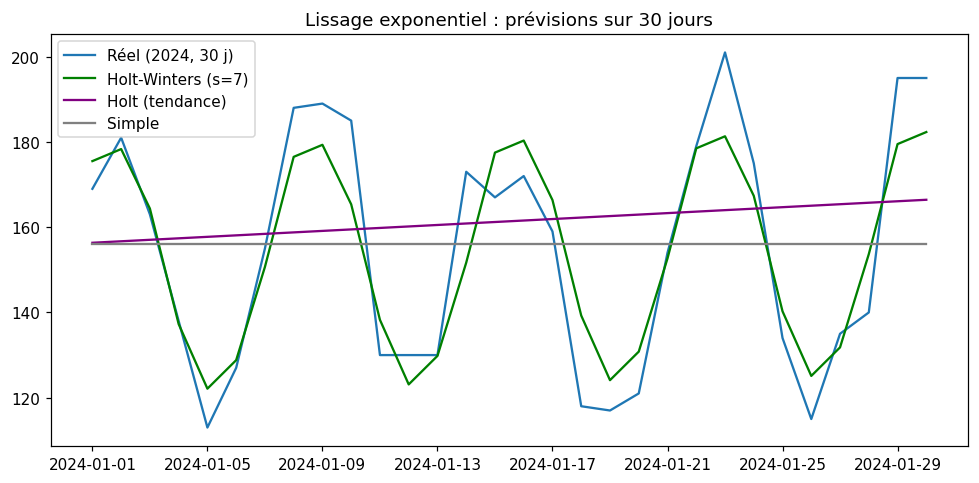

In [12]:
# Lissage exponentiel sur l'entraînement 2023 : simple, Holt (tendance), Holt-Winters (saisonnalité 7).
hw = ExponentialSmoothing(train_w, trend="add", seasonal="add", seasonal_periods=7).fit()
holt = Holt(train_w).fit()  # Holt de statsmodels 0.14 : pas de kwarg trend=, le mode par défaut est additif
simple = SimpleExpSmoothing(train_w).fit()

print("=== Lissage exponentiel — AIC ===")
print("  SimpleExpSmoothing : AIC = {:.1f}".format(simple.aic))
print("  Holt (tendance)    : AIC = {:.1f}".format(holt.aic))
print("  Holt-Winters (sais) : AIC = {:.1f}".format(hw.aic))

# Prévisions 30 jours pour comparaison.
fc_hw = hw.forecast(30)
fc_holt = holt.forecast(30)
fc_simple = simple.forecast(30)
print()
print("  MAPE 30 j : Holt-Winters = {:.1f} % | Holt = {:.1f} % | Simple = {:.1f} %".format(
    np.mean(np.abs((test[:30] - fc_hw) / test[:30])) * 100,
    np.mean(np.abs((test[:30] - fc_holt) / test[:30])) * 100,
    np.mean(np.abs((test[:30] - fc_simple) / test[:30])) * 100))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(test.index[:30], test[:30], label="Réel (2024, 30 j)")
ax.plot(test.index[:30], fc_hw, label="Holt-Winters (s=7)", color="green")
ax.plot(test.index[:30], fc_holt, label="Holt (tendance)", color="purple")
ax.plot(test.index[:30], fc_simple, label="Simple", color="gray")
ax.legend()
ax.set_title("Lissage exponentiel : prévisions sur 30 jours")
plt.tight_layout()
plt.show()

### Interprétation — comparaison hors échantillon

Sur les 30 premiers jours du run, Holt–Winters et SARIMA ont des MAPE proches de **5,6 %**, contre environ **17,5 %** pour Holt et **16,6 %** pour le lissage simple. Ce résultat descriptif concerne cette fenêtre et ces réglages ; il motive une comparaison multi-fenêtre. Holt–Winters estime aussi des états initiaux et une structure saisonnière, pas seulement trois nombres. Les AIC internes affichés ne sont pas utilisés pour classer des familles à conventions de vraisemblance différentes.

## Partie 6 : Comparaison honnête — backtest expansif

Une prévision sur **une seule** fenêtre de test peut être chanceuse. Pour comparer honnêtement, on fait un **backtest glissant** (walk-forward) : on ré-entraîne chaque modèle sur une fenêtre **expansive** et on prévoit l'horizon suivant, étape par étape. Les trois modèles testés :

- **Naïf** : la prévision est la **dernière valeur observée** répétée sur l'horizon (baseline triviale, souvent étonnamment bonne).
- **Holt-Winters** : la famille simple à saisonnalité.
- **SARIMA** : la famille ARIMA à saisonnalité.

On garde **12 fenêtres de 7 jours**, soit 84 jours de test. Chaque modèle est réajusté sur le passé disponible, avec les ordres SARIMA sélectionnés sur 2023 ; aucune observation future n'entre dans les ajustements de ces modèles conditionnés aux choix fixés. Le naïf répète la dernière valeur observée. Le choix de sept jours expose le cycle hebdomadaire ; il ne prétend pas que toutes les prévisions à un jour seraient identiques. Une égalité après arrondi à deux décimales n'est pas une équivalence statistique démontrée.


Les diagnostics globaux précédents ont vu 2024. La séparation des données d’ajustement ne prouve donc pas ici l’absence de fuite d’un **pipeline entier de sélection** ; cette limite est distincte de l’intégrité des douze réajustements sur le passé.


In [13]:
# Backtest glissant (walk-forward) : fenêtre expansive, horizon 7 jours, ~12 pas.
# Ré-entraîne SARIMA + Holt-Winters à chaque pas, compare à la baseline naïve.
# Horizon 7 (une semaine) : c'est ce qui fait discriminer — sur 1 jour, toutes les
# prévisions valent la dernière valeur et la comparaison devient dégénérée.
import time

t0 = time.time()
folds = 12  # 12 fenêtres de 7 jours (84 points de test), budget CPU raisonnable
H = 7
start_idx = len(train)  # premier index de test

mape_naive, mape_hw, mape_sarima = [], [], []
by_fold = []
for k in range(folds):
    idx = start_idx + k * H
    past = sales.iloc[:idx]
    y_true = sales.iloc[idx:idx + H]
    if len(y_true) < H:
        break

    # Naïf : on répète la dernière valeur observée sur l'horizon.
    naive = np.full(H, past.iloc[-1])
    mape_naive.append(np.mean(np.abs((y_true - naive) / y_true)))

    # Holt-Winters (saisonnalité 7) — ré-entraîné.
    f_hw = ExponentialSmoothing(past, trend="add", seasonal="add", seasonal_periods=7).fit().forecast(H)
    mape_hw.append(np.mean(np.abs((y_true - f_hw) / y_true)))

    # SARIMA (meilleure config) — ré-entraîné.
    f_sar = SARIMAX(past, order=best_order, seasonal_order=best_sorder).fit(disp=False).forecast(H)
    mape_sarima.append(np.mean(np.abs((y_true - f_sar) / y_true)))

    by_fold.append((round(mape_naive[-1] * 100, 2), round(mape_hw[-1] * 100, 2), round(mape_sarima[-1] * 100, 2)))

elapsed = time.time() - t0
print("=== Backtest glissant ({:.1f}s, {} fenêtres de {}j) — MAPE moyen ===".format(elapsed, len(mape_naive), H))
print("  Naïf        : {:.2f} %".format(np.mean(mape_naive) * 100))
print("  Holt-Winters: {:.2f} %".format(np.mean(mape_hw) * 100))
print("  SARIMA      : {:.2f} %".format(np.mean(mape_sarima) * 100))
print()
m_naive = np.mean(mape_naive) * 100
m_hw = np.mean(mape_hw) * 100
m_sar = np.mean(mape_sarima) * 100
scores = {"Naïf": round(m_naive, 2), "Holt-Winters": round(m_hw, 2), "SARIMA": round(m_sar, 2)}
best = min(scores.values())  # ex aequo a la precision d'affichage : argmin tranchait au 1e-9 pres
winners = [n for n, m in scores.items() if m == best]
print("Gagnant (MAPE moyen) : {} ({:.2f} %){}".format(" = ".join(winners), best, "  <- ex aequo" if len(winners) > 1 else ""))
nb_naive = sum(1 for m in by_fold if m[0] == min(m))
nb_hw = sum(1 for m in by_fold if m[1] == min(m))
nb_sar = sum(1 for m in by_fold if m[2] == min(m))
print("Fenêtres où chaque modèle est le meilleur : Naïf {} | Holt-Winters {} | SARIMA {}".format(nb_naive, nb_hw, nb_sar))
print("Écart naïf -> meilleur modèle : {:.2f} pts de MAPE".format(m_naive - min(m_hw, m_sar)))
print("Table (fenêtre : Naïf / HW / SARIMA) : {}".format(by_fold))
print()
print("Lecture : les écarts sont mesurés sur douze fenêtres ; une égalité après arrondi ne prouve pas l’équivalence.")
print("Aucun repli silencieux vers le naïf : chaque erreur HW/SARIMA provient d’un vrai ajustement.")


=== Backtest glissant (3.5s, 12 fenêtres de 7j) — MAPE moyen ===
  Naïf        : 15.98 %
  Holt-Winters: 5.82 %
  SARIMA      : 5.82 %

Gagnant (MAPE moyen) : Holt-Winters = SARIMA (5.82 %)  <- ex aequo
Fenêtres où chaque modèle est le meilleur : Naïf 0 | Holt-Winters 12 | SARIMA 12
Écart naïf -> meilleur modèle : 10.15 pts de MAPE
Table (fenêtre : Naïf / HW / SARIMA) : [(np.float64(14.34), np.float64(2.71), np.float64(2.71)), (np.float64(17.12), np.float64(6.63), np.float64(6.63)), (np.float64(23.25), np.float64(7.17), np.float64(7.17)), (np.float64(17.47), np.float64(5.7), np.float64(5.7)), (np.float64(15.58), np.float64(7.26), np.float64(7.26)), (np.float64(14.64), np.float64(4.71), np.float64(4.71)), (np.float64(17.94), np.float64(6.23), np.float64(6.23)), (np.float64(12.95), np.float64(4.74), np.float64(4.74)), (np.float64(15.43), np.float64(5.46), np.float64(5.46)), (np.float64(14.66), np.float64(7.82), np.float64(7.82)), (np.float64(18.75), np.float64(5.24), np.float64(5.24)), (

### Interprétation du backtest

Le run donne environ **15,98 %** de MAPE au naïf contre **5,82 %** aux deux modèles saisonniers, à la précision de l'affichage. Les victoires par fenêtre comptent les ex aequo : leur somme peut dépasser douze. Cette proximité ne prouve ni identité des prévisions ni absence générale de gain à utiliser SARIMA. La configuration sélectionnée a ici p=0 : attribuer son écart à un « ordre AR ajouté » serait même inexact. La conclusion utile est limitée : sur ces douze fenêtres et ces configurations, le modèle plus complexe n'apporte pas de gain visible à la précision retenue. Un autre horizon, une autre série et une estimation d'incertitude pourraient changer cette lecture.

### Exercice 4 — bonus 24 fenêtres

Rejouez le même protocole expansif sur 24 fenêtres de sept jours, sans changer les données ni regarder le futur. Renvoyez les tailles de passé et les trois erreurs par fenêtre ; une observation textuelle seule ne prouve pas les réajustements. Comparez les moyennes et ex aequo au protocole à douze fenêtres, sans imposer le résultat.


In [14]:
# Exercice 4 (bonus) : augmenter les fenêtres, sans fabriquer une observation
# TODO étudiant : Étape 1 réajuster24fois ; Étape 2 garder le passé seul ; Étape 3 comparer les erreurs calculées.
def backtest_bonus(values, start, folds, horizon):
    return None  # TODO étudiant : lignes (taille_passé, MAPE_naïf, MAPE_HW, MAPE_SARIMA)

def verifier_bonus(response):
    try:
        actual = response(sales.to_numpy().copy(), len(train), 24, 7)
        if actual is None:
            return False
        a = np.asarray(actual)
        if a.shape != (24, 4) or not np.isfinite(a).all():
            return False
        expected = []
        for k in range(24):
            idx = len(train) + 7*k
            past = sales.to_numpy()[:idx]
            truth = sales.to_numpy()[idx:idx+7]
            naive = np.full(7, past[-1])
            hw_model = ExponentialSmoothing(past, trend="add", seasonal="add", seasonal_periods=7).fit()
            sar_model = SARIMAX(past, order=best_order, seasonal_order=best_sorder).fit(disp=False)
            errors = [np.mean(np.abs((truth-fc)/truth))*100 for fc in (naive, hw_model.forecast(7), sar_model.forecast(7))]
            expected.append([idx, *errors])
        return bool(np.allclose(a, expected, rtol=0, atol=1e-6))

    except (TypeError, ValueError, OverflowError, AttributeError, IndexError, KeyError):
        return False

print("Exercice 4 à compléter" if backtest_bonus(sales.to_numpy(), len(train), 24, 7) is None else f"Bonus valide : {verifier_bonus(backtest_bonus)}")


Exercice 4 à compléter


## Conclusion et pont vers la suite

Ce carnet relie six activités : décomposer ; examiner une racine unité ; lire ACF/PACF ; ajuster SARIMA et diagnostiquer ses résidus ; comparer les trois lissages ; tester hors échantillon sur un passé expansif. Les diagnostics orientent les choix, sans produire de preuve universelle de stationnarité ou de domination d'un modèle.

| Direction | Carnet | Prolongement |
|---|---|---|
| SSA en ML.NET | [ML-05 C#](ML-05-TimeSeries-CSharp.ipynb) | autre modèle natif, qui ne remplace pas ADF/SARIMA |
| Application STL/SARIMA | [ML-05 Python](ML-05-TimeSeries-Python.ipynb) | application et intervalles |
| Famille quant | [Index QuantConnect](../../QuantConnect/README.md) | protocoles hors échantillon et modèles temporels |

## À retenir

ADF non rejeté ne prouve pas H0 ; un seuil d'ACF/PACF ne sélectionne pas seul un ordre ; une p-value résiduelle ne certifie pas un bruit blanc ; un arrondi commun ne prouve pas l'équivalence de deux prévisions. Les modèles réels et le backtest sans repli rendent ces limites vérifiables.

## Vérifiez votre compréhension

1. Un cycle de sept jours impose-t-il D=1 ?
<details><summary>Réponse</summary>Non : saisonnalité déterministe et racine unité saisonnière sont distinctes ; la grille fixe D=1 comme choix à évaluer.</details>

2. Pourquoi exclure le retard zéro de la liste PACF ?
<details><summary>Réponse</summary>Il vaut 1 par définition et ne diagnostique pas une relation entre dates distinctes.</details>

3. Deux MAPE affichées à 5,82 % prouvent-elles des prévisions identiques ?
<details><summary>Réponse</summary>Non : l'arrondi masque des différences et le protocole n'établit pas une équivalence statistique.</details>

## Pour aller plus loin

Comparer d'autres horizons, contrôler une différenciation saisonnière et ajuster les degrés de liberté du diagnostic ; suivre les trois liens du tableau pour les applications.
